**Naive Bayes**

In [18]:
from sklearn.datasets import load_breast_cancer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             classification_report,
                             ConfusionMatrixDisplay
                             )

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state = 75, stratify=y)

In [20]:
from sklearn.preprocessing import StandardScaler

scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.fit_transform(X_test)

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train_scaled,y_train)
y_pred = model.predict(X_test_scaled)

In [22]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

['GaussianNB']
              precision    recall  f1-score   support

   malignant       0.91      0.91      0.91        64
      benign       0.94      0.94      0.94       107

    accuracy                           0.93       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.93      0.93      0.93       171

['MultinomialNB']
              precision    recall  f1-score   support

   malignant       0.98      0.88      0.93        64
      benign       0.93      0.99      0.96       107

    accuracy                           0.95       171
   macro avg       0.96      0.93      0.94       171
weighted avg       0.95      0.95      0.95       171

['KNN']
              precision    recall  f1-score   support

   malignant       0.86      0.95      0.90        64
      benign       0.97      0.91      0.94       107

    accuracy                           0.92       171
   macro avg       0.91      0.93      0.92       171
weighted avg       0.93      0.92

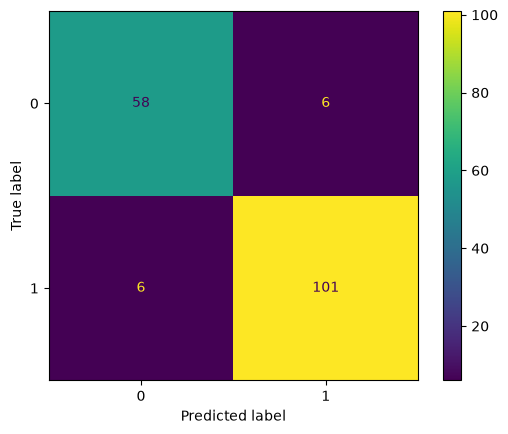

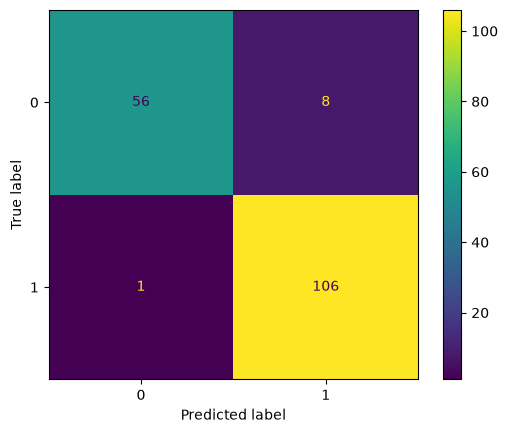

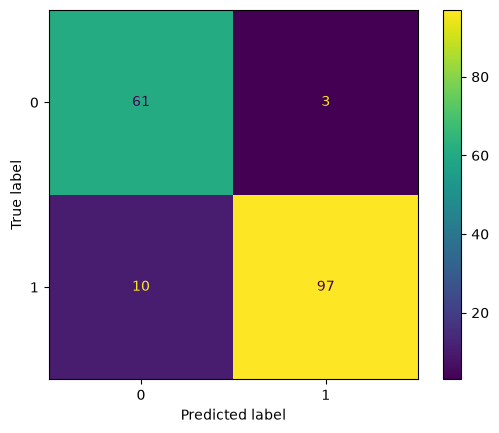

In [27]:
models = {
    "GaussianNB" : GaussianNB(),
    "MultinomialNB" : MultinomialNB(),
    "KNN" : KNeighborsClassifier()
}

result = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred
    result[name] = {
        "Accuracy" : accuracy_score,
        "Precision" : precision_score(y_test,y_pred,zero_division=0),
        "Recall" : recall_score(y_test,y_pred,zero_division=0),
        "f1_score" :f1_score(y_test,y_pred,zero_division=0),
        "ConfusionMatrixDisplay" : ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
    }
    print([name])
    print(classification_report(y_test,y_pred,target_names=data.target_names,zero_division=0))

